In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Ruta a la carpeta del proyecto (una carpeta "arriba" de notebooks/)
RUTA = ".."

df = pd.read_csv(f"{RUTA}/data/processed/dataset_final.csv")

# El CSV guarda las fechas como texto, así que las convertimos
df["datetime"] = pd.to_datetime(df["datetime"], utc=True)
df["datetime"] = df["datetime"].dt.tz_convert("Europe/Madrid")
df = df.set_index("datetime")

print(df.shape)
print(df.head())


(24783, 2)
                             demanda_mw  temperatura
datetime                                            
2024-01-01 00:00:00+01:00  23352.166667          4.6
2024-01-01 01:00:00+01:00  22610.750000          4.3
2024-01-01 02:00:00+01:00  21386.083333          4.1
2024-01-01 03:00:00+01:00  20141.333333          3.6
2024-01-01 04:00:00+01:00  19354.583333          3.1


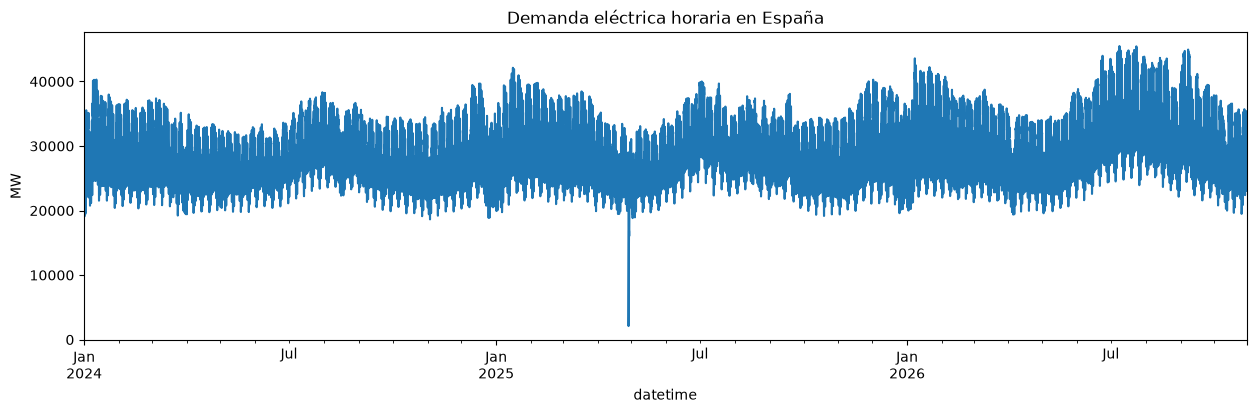

In [2]:
# Gráfica de línea de toda la serie
df["demanda_mw"].plot(figsize=(15, 4), title="Demanda eléctrica horaria en España")
plt.ylabel("MW")
plt.show()
#La variable objetivo demanda_mw es la potencia media horaria demandada en el sistema peninsular (MW). Al ser valores horarios, coincide numéricamente con la energía consumida en cada hora (MWh).

In [3]:
#Como la fecha está en el índice (no en una columna), en lugar de df["datetime"].dt.hour se usa directamente df.index.hour
df["hora"] = df.index.hour


### Observaciones
- La demanda oscila habitualmente entre ~20.000 y ~45.000 MW.
- Se repiten **dos picos anuales**: invierno (enero) y verano (julio–agosto).
- Primavera y otoño son los periodos de menor demanda.
- El verano de 2026 alcanza el máximo del periodo (~45.000 MW).
- ⚡ Caída extrema el **de abril de 2025** (~2.000 MW): el apagón de la península ibérica.

### Interpretación
- Invierno: mayor uso de calefacción e iluminación (menos horas de luz).
- Verano: uso intensivo de aire acondicionado.
- Primavera y otoño: temperaturas suaves, sin necesidad de climatización.
- La relación demanda–temperatura no es lineal: tiene **forma de U** (se consume
  más con frío intenso y con calor intenso).

### Implicación para el modelo
- La **temperatura** y el **mes** serán variables clave.
- Como la relación con la temperatura tiene forma de U, un modelo lineal simple
  la captará mal.
- El apagón es un **outlier** no predecible: debe excluirse del entrenamiento o
  marcarse, para que no distorsione el modelo.


¿A que hora se consume más?

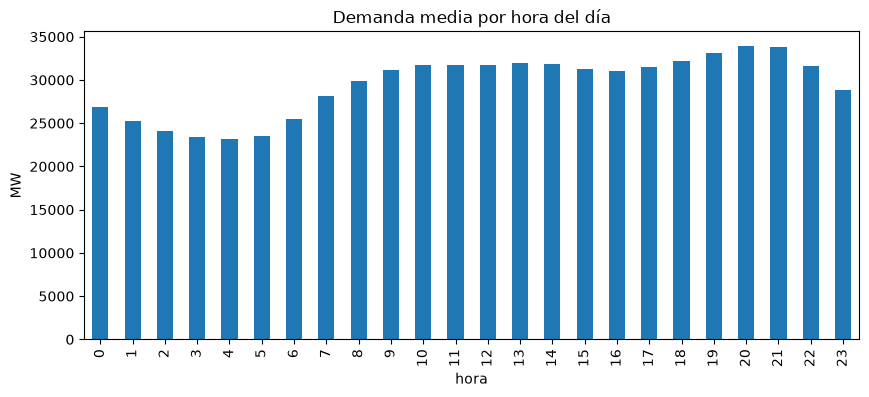

In [4]:
# Agrupamos por hora y calculamos la demanda media de cada hora
demanda_por_hora = df.groupby("hora")["demanda_mw"].mean()

demanda_por_hora.plot(kind="bar", figsize=(10, 4), title="Demanda media por hora del día")
plt.ylabel("MW")
plt.show()


### Observaciones
- Mínimo entre las 3 y las 5 h (~23.000 MW).
- Subida rápida entre las 7 y las 9 h.
- Meseta entre las 10 y las 14 h (~32.000 MW) y ligera bajada a las 15–16 h.
- **Pico máximo a las 20–21 h** (~34.000 MW).

### Interpretación
- Madrugada: la mayoría de la población duerme y la actividad es mínima.
- Mañana: comienzo de la jornada laboral e industrial.
- Bajada de media tarde: pausa para comer.
- Pico nocturno: coinciden en los hogares cocina, iluminación y
  electrodomésticos; es tarde por los horarios españoles.
- El valle relativo de mediodía es coherente con el **autoconsumo fotovoltaico**,
  que reduce la energía demandada a la red en las horas de más radiación.

### Implicación para el modelo
- La **hora** es probablemente la variable más importante: explica gran parte de
  la variación diaria.
- El patrón no es lineal (sube, baja y vuelve a subir), lo que refuerza el uso de
  modelos de árboles.


In [5]:
#Creo graficas de dias de la semana y mes
# La fecha está en el índice, así que usamos df.index en vez de df["datetime"].dt
df["hora"] = df.index.hour
df["dia_semana"] = df.index.dayofweek   # 0 = lunes ... 6 = domingo
df["mes"] = df.index.month              # 1 = enero ... 12 = diciembre


/var/folders/ld/g1s837zd4szbbnm9hty5h28c0000gn/T/ipykernel_81318/694623089.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df["dia_semana"] = df.index.dayofweek   # 0 = lunes ... 6 = domingo


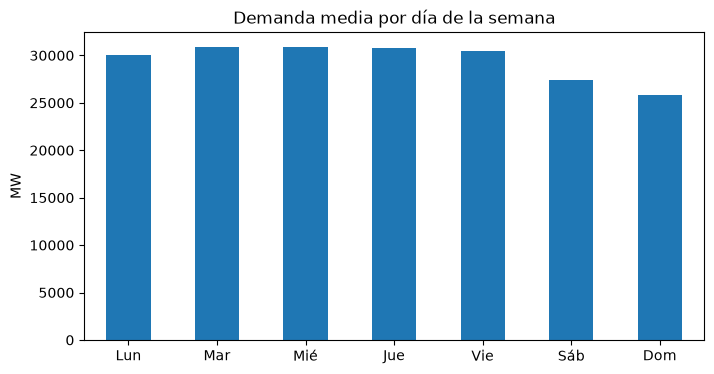

In [6]:

# Agrupamos por día de la semana y calculamos la media
demanda_por_dia = df.groupby("dia_semana")["demanda_mw"].mean()

# Ponemos nombres en lugar de números para que se entienda mejor
demanda_por_dia.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

demanda_por_dia.plot(kind="bar", figsize=(8, 4), title="Demanda media por día de la semana")
plt.ylabel("MW")
plt.xticks(rotation=0)   # etiquetas en horizontal
plt.show()


### Observaciones
- De lunes a viernes la demanda es estable y alta.
- El sábado baja y el **domingo es el día de menor demanda**.

### Interpretación
- Los fines de semana cierran oficinas, comercios y buena parte de la industria,
  que son grandes consumidores.
- El consumo doméstico aumenta, pero no compensa la caída del consumo industrial
  y de servicios.

### Implicación para el modelo
- El **día de la semana** es una variable útil, sobre todo para distinguir
  laborables de fines de semana.
- Mejora posible: añadir una variable de **festivos nacionales**, que se comportan
  como un domingo.


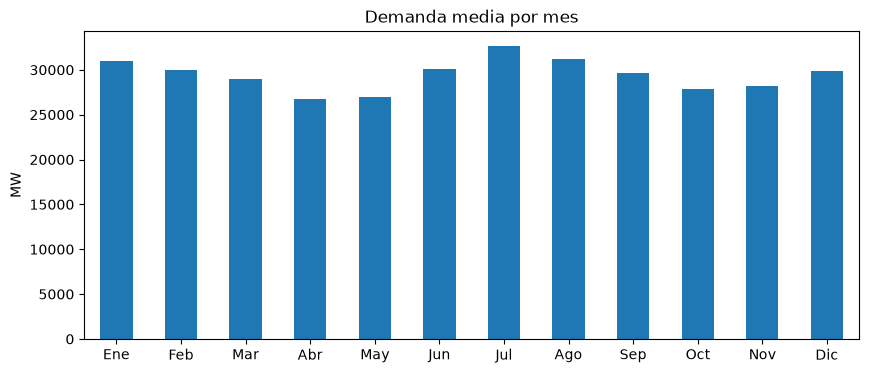

In [7]:
# Agrupamos por mes y calculamos la media
demanda_por_mes = df.groupby("mes")["demanda_mw"].mean()

demanda_por_mes.index = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                         "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

demanda_por_mes.plot(kind="bar", figsize=(10, 4), title="Demanda media por mes")
plt.ylabel("MW")
plt.xticks(rotation=0)
plt.show()


###  Observaciones
- Los meses de mayor demanda son **enero** y **julio–agosto**.
- Los de menor demanda son **abril–mayo** y **octubre–noviembre**.
- El patrón muestra **dos picos anuales**, confirmando lo observado en la serie
  completa.

###  Interpretación
- Los picos coinciden con las estaciones de climatización (calefacción en invierno,
  aire acondicionado en verano).
- Los valles coinciden con las estaciones de temperatura suave.
- Agosto puede ser algo menor de lo esperado por las vacaciones (menos actividad
  industrial y de oficinas).

###  Implicación para el modelo
- El **mes** recoge la estacionalidad anual.
- Gran parte de su efecto lo explica la temperatura, así que ambas variables
  estarán relacionadas. El modelo usará las dos, y el mes aportará lo que la
  temperatura no explica (vacaciones, horas de luz).


# Gráfico de dispersión de temperatura frente a demanda

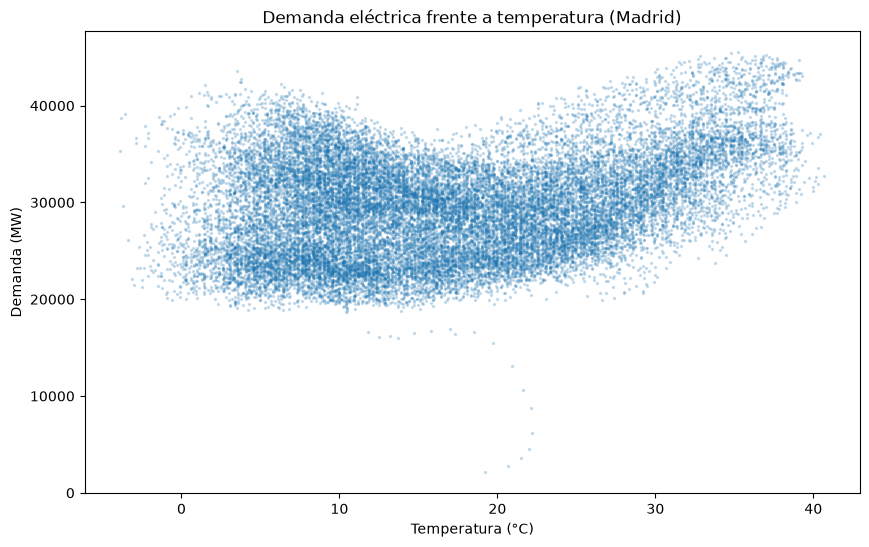

In [8]:
# Cada punto es una hora: en el eje X su temperatura y en el Y su demanda
plt.figure(figsize=(10, 6))
plt.scatter(df["temperatura"], df["demanda_mw"], s=2, alpha=0.2)

plt.title("Demanda eléctrica frente a temperatura (Madrid)")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Demanda (MW)")
plt.show()


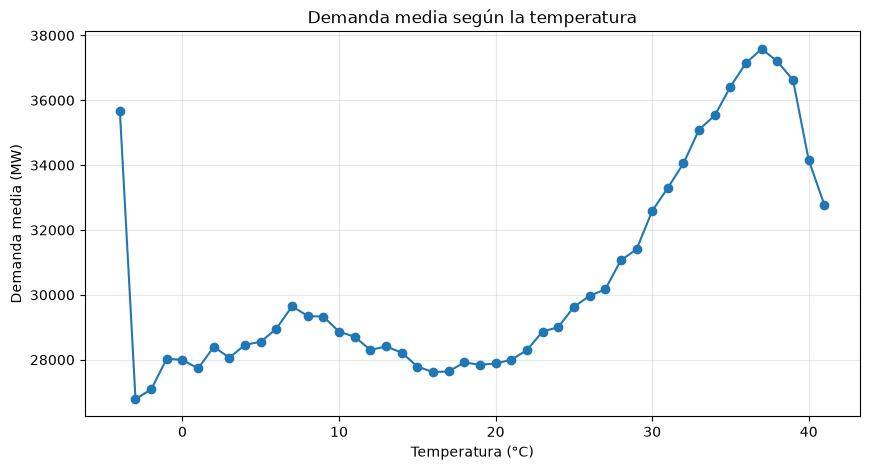

In [9]:
# Redondeamos la temperatura a grados enteros y calculamos la demanda media de cada grado
demanda_por_temp = df.groupby(df["temperatura"].round())["demanda_mw"].mean()

plt.figure(figsize=(10, 5))
demanda_por_temp.plot(marker="o")
plt.title("Demanda media según la temperatura")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Demanda media (MW)")
plt.grid(alpha=0.3)
plt.show()


In [10]:
#correlación
#La correlación es un número entre −1 y 1 que mide la relación lineal entre dos variables:

#1: cuando una sube, la otra sube.
#−1: cuando una sube, la otra baja.
#0: no hay relación lineal.


print(df["temperatura"].corr(df["demanda_mw"]))


0.3018783364573683
